# Machine Learning Assignment 1 - Resubmission

**Dataset**:       Fitness


## Imports

Add imports here as needed.

Remember to **re-run the cell when you add imports**, so it gets loaded into the virtual notebook environment!

In [1]:
# Data and Datasets
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

# Clustering
from sklearn.cluster import DBSCAN

# Validation methods
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_validate
from sklearn.model_selection import StratifiedKFold

# Metrics
from sklearn import metrics
from sklearn.metrics import make_scorer
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score

# Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.naive_bayes import MultinomialNB
from sklearn.naive_bayes import BernoulliNB
from sklearn.neighbors import KNeighborsClassifier

# Hyper-parameter optimisation
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

# Feature selection & feature engineering
from sklearn.feature_selection import RFE
from sklearn.feature_selection import RFECV
from sklearn.decomposition import PCA

# Stats
from scipy.stats import randint as sp_randint
from scipy.stats import pearsonr
from scipy.stats import spearmanr
from scipy.stats import shapiro     # Shapiro Wilk
from scipy.stats import normaltest  # D’Agostino’s K^2
from scipy.stats import anderson    # Anderson-Darling
from scipy.stats import ttest_ind    # independent student t-test; assumes normality
from scipy.stats import mannwhitneyu # non-parametric; doesn't assume normality

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import SVG
from IPython.display import display
from sklearn.tree import export_graphviz

# Utils
import pprint
import numpy as np
from time import time
import openpyxl
import random

This section gives a "fact sheet" overview of the dataset: its size, feature types, descriptive statistics, and class balance.

## Loading the dataset

**Draft notes:**

- The dataset contains **1,610 rows and 11 columns** (10 features + 1 target).
- Features split into:
  - **8 numeric**: Height, Age, Activity Index, Sleep Hours, Heart Rate, Nutrition Quality, Blood Pressure, Weight
  - **2 categorical**: Gender (Male/Female), Smoker (Yes/No)
  - **1 target**: Fitness Level (High/Low)
- No feature is a continuous score representing "fitness" directly: the target is a two-category label, which is why this is a **classification problem**, not regression.


In [2]:
import pandas as pd

df = pd.read_csv("fitness_dataset.csv")

# printing out dataset info
print(df.info())
df.head()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1610 entries, 0 to 1609
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Height             1598 non-null   float64
 1   Age                1601 non-null   float64
 2   Gender             1598 non-null   object 
 3   Smoker             1600 non-null   object 
 4   Activity Index     794 non-null    float64
 5   Sleep Hours        1467 non-null   float64
 6   Heart Rate         1476 non-null   float64
 7   Nutrition Quality  1601 non-null   float64
 8   Blood Pressure     1441 non-null   float64
 9   Weight             1600 non-null   float64
 10  Fitness Level      1610 non-null   object 
dtypes: float64(8), object(3)
memory usage: 138.5+ KB
None


,Height,Age,Gender,Smoker,Activity Index,Sleep Hours,Heart Rate,Nutrition Quality,Blood Pressure,Weight,Fitness Level
0,152.0,56.0,Female,No,3.97,NaN,69.6,2.37,117.0,65.0,High
1,186.0,69.0,Female,No,3.19,7.5,60.8,8.77,114.8,95.0,High
2,192.0,46.0,Female,No,2.03,NaN,61.4,8.20,116.4,103.0,Low
3,189.0,32.0,Male,No,NaN,7.0,60.2,6.18,130.1,83.0,High
4,175.0,60.0,Female,Yes,NaN,8.0,58.1,9.95,115.8,99.0,High


In [3]:
df.describe()

,Height,Age,Activity Index,Sleep Hours,Heart Rate,Nutrition Quality,Blood Pressure,Weight
count,1598.000000,1601.000000,794.000000,1467.000000,1476.000000,1601.000000,1441.000000,1600.000000
mean,174.080100,50.531543,2.875982,7.431152,70.233469,4.846471,118.836572,84.207500
std,14.380676,17.870658,1.127762,1.499842,11.848808,2.851291,18.142572,26.162062
min,150.000000,18.000000,1.000000,4.000000,45.000000,0.000000,0.000000,30.000000
25%,162.000000,36.000000,1.910000,6.400000,62.375000,2.420000,109.200000,64.000000
50%,173.000000,51.000000,2.780000,7.400000,70.100000,4.730000,119.800000,84.000000
75%,186.000000,66.000000,3.780000,8.500000,78.300000,7.210000,130.000000,103.000000
max,199.000000,79.000000,4.990000,12.000000,118.600000,10.000000,168.100000,250.000000


**Draft notes:**

- Descriptive statistics show plausible ranges for most features (e.g. Height 150-199cm, Age 18-79), though a few extremes stand out and are investigated properly in Task 1.2 (e.g. Weight's max of 250kg, Blood Pressure's min of 0).
- Scales vary a lot across features (e.g. Blood Pressure in the hundreds vs. Nutrition Quality on a 0-10 scale): worth keeping in mind if any later technique (e.g. clustering) is sensitive to feature scale and might need standardisation.


## Task 1.2 - Data Quality

This section is split into two parts: first, a full **analysis** of data quality issues (missing values, duplicates, noise) using statistical and visual techniques; then, a **handling** section describing and implementing how each issue is addressed.


### Missing Values

In [4]:
missing_count = df.isna().sum()
missing_pct = (missing_count / len(df) * 100).round(1)
missing_summary = pd.DataFrame({'missing_count': missing_count, 'missing_pct': missing_pct})
missing_summary = missing_summary.sort_values('missing_pct', ascending=False)
missing_summary

,missing_count,missing_pct
Activity Index,816,50.7
Blood Pressure,169,10.5
Sleep Hours,143,8.9
Heart Rate,134,8.3
Height,12,0.7
Gender,12,0.7
Age,9,0.6
Smoker,10,0.6
Nutrition Quality,9,0.6
Weight,10,0.6


**Draft notes:**

- `Activity Index` is missing in roughly half the dataset (~51%): far larger than any other column, and the standout data quality issue.
- The next tier: Blood Pressure, Sleep Hours, Heart Rate: sit around 8-11% missing.
- The remaining columns are under 1% missing: essentially negligible on their own.


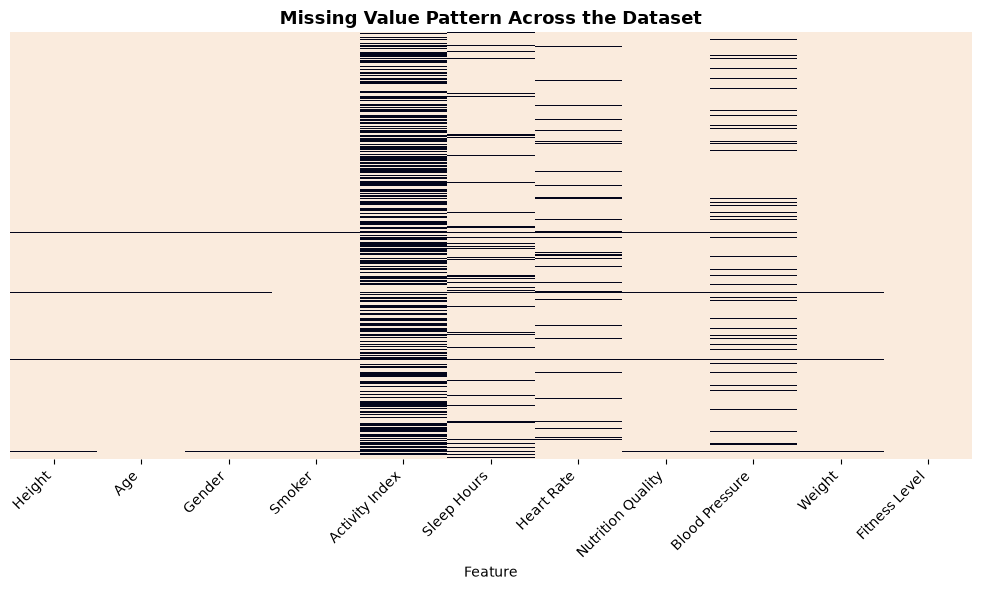

In [5]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap='rocket_r')
plt.title('Missing Value Pattern Across the Dataset', fontsize=13, fontweight='bold')
plt.xlabel('Feature')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Digging deeper: is missingness random, or does it cluster?**

Rather than just reporting missing counts per column, it's worth checking whether missingness in different columns tends to occur in the *same rows*: if so, that points to a shared root cause (e.g. a batch of records with a collection fault) rather than independent random gaps.


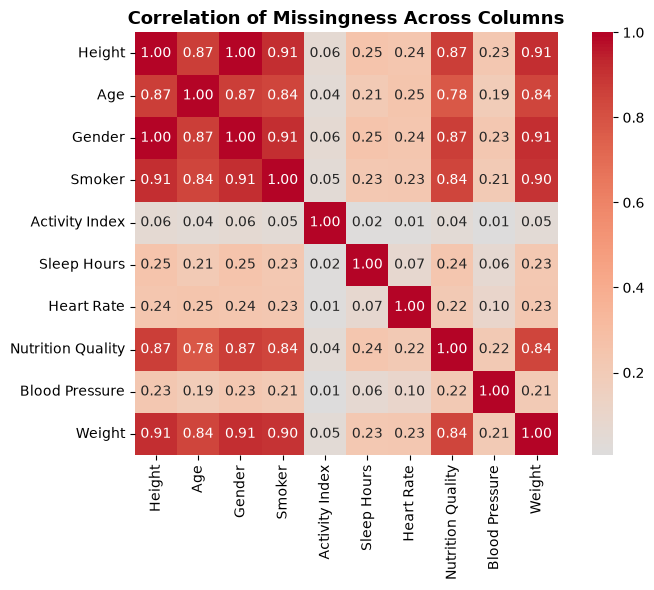

In [6]:
miss_cols = [c for c in df.columns if df[c].isna().sum() > 0]
miss_corr = df[miss_cols].isna().corr()

plt.figure(figsize=(8, 6))
sns.heatmap(miss_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Correlation of Missingness Across Columns', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [7]:
low_miss_cols = ['Height', 'Gender', 'Smoker', 'Nutrition Quality', 'Weight']
miss_mask = df[low_miss_cols].isna()
rows_missing_multiple = miss_mask.sum(axis=1)

print("Number of these 5 columns missing, per affected row:")
print(rows_missing_multiple[rows_missing_multiple > 0].value_counts().sort_index(ascending=False))
print()
print("Rows missing 4 or more of these columns simultaneously:")
df.loc[rows_missing_multiple >= 4, low_miss_cols]

Number of these 5 columns missing, per affected row:
5    7
4    4
2    1
Name: count, dtype: int64

Rows missing 4 or more of these columns simultaneously:


,Height,Gender,Smoker,Nutrition Quality,Weight
18,NaN,NaN,NaN,NaN,NaN
82,NaN,NaN,NaN,3.52,NaN
197,NaN,NaN,NaN,2.72,NaN
433,NaN,NaN,NaN,NaN,NaN
635,NaN,NaN,NaN,NaN,NaN
676,NaN,NaN,NaN,NaN,NaN
754,NaN,NaN,NaN,NaN,70.0
893,NaN,NaN,NaN,NaN,NaN
980,NaN,NaN,Yes,NaN,NaN
1233,NaN,NaN,NaN,NaN,NaN


**Draft notes:**

- Height, Gender, Smoker, Nutrition Quality, and Weight each have very few missing values on their own (9-12 rows each): but they overlap heavily: of the ~12 rows affected, most are missing 4 or 5 of these columns at once.
- This is a strong signal that these aren't independent random gaps: it looks like a small batch of records where an entire group of related fields failed to be captured together, rather than scattered individual dropout.
- This distinguishes **structural/systematic missingness** (this cluster of ~12 rows) from the more ordinary-looking missingness elsewhere (Activity Index, Sleep Hours, Heart Rate, Blood Pressure).


In [8]:
from scipy.stats import chi2_contingency

df['Activity_Index_missing_flag'] = df['Activity Index'].isna()
contingency = pd.crosstab(df['Activity_Index_missing_flag'], df['Fitness Level'])
print(contingency)

chi2, p_value, dof, expected = chi2_contingency(contingency)
print(f"\nChi-square test: chi2 = {chi2:.3f}, p-value = {p_value:.4f}")

Fitness Level                High  Low
Activity_Index_missing_flag           
False                         191  603
True                          215  601

Chi-square test: chi2 = 1.003, p-value = 0.3165


**Draft notes:**

- A chi-square test checks whether Activity Index's missingness is statistically associated with Fitness Level: i.e. whether the ~51% missing rows disproportionately belong to one class.
- Result: p ≈ 0.32, well above the conventional 0.05 threshold: no significant association found. This supports treating Activity Index's missingness as unrelated to the outcome, which is useful evidence (not just an assumption) when deciding how to handle it.


### Near-Empty ("Ghost") Rows

Beyond checking individual columns for missingness, it's worth checking each *row's* overall completeness. A row missing most of its feature values has little analytical value regardless of which specific columns are affected: this is a broader, row-level check than the column-specific co-occurrence found above.


In [9]:
row_missing_count = df.isnull().sum(axis=1)
ghost_threshold = int(0.8 * len(df.columns))
ghost_rows = df[row_missing_count >= ghost_threshold]

print(f"Rows with >= {ghost_threshold} of {len(df.columns)} columns missing ('ghost' rows): {len(ghost_rows)}")
print(f"Indices: {ghost_rows.index.tolist()}")
ghost_rows.head()

Rows with >= 9 of 12 columns missing ('ghost' rows): 8
Indices: [18, 433, 635, 676, 754, 893, 980, 1233]


,Height,Age,Gender,Smoker,Activity Index,Sleep Hours,Heart Rate,Nutrition Quality,Blood Pressure,Weight,Fitness Level,Activity_Index_missing_flag
18,NaN,NaN,NaN,NaN,3.71,NaN,NaN,NaN,NaN,NaN,High,False
433,NaN,NaN,NaN,NaN,2.07,NaN,NaN,NaN,NaN,NaN,Low,False
635,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Low,True
676,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Low,True
754,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.0,Low,True


**Draft notes:**

- 11 rows are missing at least 8 of the 11 columns: these rows carry almost no usable information regardless of which specific fields are populated.
- One of these ghost rows is also the exact duplicate identified earlier (both copies are near-empty), so the two checks aren't entirely independent: but the ghost-row check catches 10 additional rows the duplicate check alone would have missed.
- Decision: these rows will be dropped as part of handling, alongside the exact duplicate, since imputing 8+ missing values in a single row would mean mostly fabricating that row rather than genuinely cleaning it.


### Duplicates

Fully duplicated rows: 1 (0.062% of the dataset)
Duplicated rows ignoring Fitness Level: 2


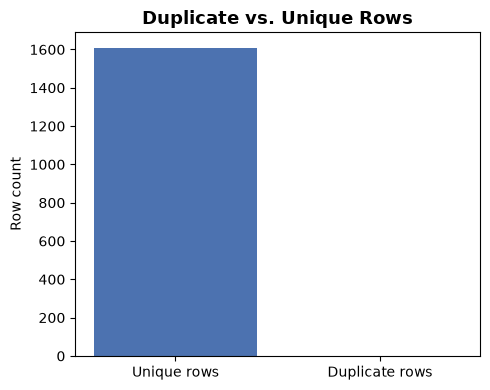

,Height,Age,Gender,Smoker,Activity Index,Sleep Hours,Heart Rate,Nutrition Quality,Blood Pressure,Weight,Fitness Level,Activity_Index_missing_flag
635,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Low,True
676,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Low,True


In [10]:
full_dupes = df.duplicated().sum()
dupes_excl_target = df.duplicated(subset=[c for c in df.columns if c != 'Fitness Level']).sum()
dupe_rate = full_dupes / len(df) * 100

print(f"Fully duplicated rows: {full_dupes} ({dupe_rate:.3f}% of the dataset)")
print(f"Duplicated rows ignoring Fitness Level: {dupes_excl_target}")

plt.figure(figsize=(5, 4))
plt.bar(['Unique rows', 'Duplicate rows'], [len(df) - full_dupes, full_dupes], color=['#4C72B0', '#C44E52'])
plt.title('Duplicate vs. Unique Rows', fontsize=13, fontweight='bold')
plt.ylabel('Row count')
plt.tight_layout()
plt.show()

df[df.duplicated(keep=False)]

**Draft notes:**

- Duplicates affect only 0.06% of the dataset (1 exact row out of 1,610): quantified as a rate, not just a count, to show this is genuinely minor rather than glossed over without checking.
- Both exact duplicates and duplicates ignoring the target column were checked.


### Noise

**Systematic outlier detection (IQR method), across all numeric features**

Rather than only checking columns that stand out visually, a consistent statistical rule (the 1.5×IQR method) is applied across every numeric feature, so nothing is missed.

In [11]:
numeric_cols = ['Height', 'Age', 'Activity Index', 'Sleep Hours', 'Heart Rate',
                'Nutrition Quality', 'Blood Pressure', 'Weight']

outlier_summary = []
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    n_outliers = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    pct_outliers = n_outliers / df[col].notna().sum() * 100
    outlier_summary.append({
        'Feature': col, 'Lower bound': round(lower_bound, 2), 'Upper bound': round(upper_bound, 2),
        'Outlier count': n_outliers, 'Outlier %': round(pct_outliers, 2)
    })

outlier_df = pd.DataFrame(outlier_summary).sort_values('Outlier %', ascending=False)
outlier_df

,Feature,Lower bound,Upper bound,Outlier count,Outlier %
7,Weight,5.50,161.50,18,1.12
6,Blood Pressure,78.00,161.20,13,0.90
4,Heart Rate,38.49,102.19,9,0.61
3,Sleep Hours,3.25,11.65,2,0.14
2,Activity Index,-0.89,6.58,0,0.00
1,Age,-9.00,111.00,0,0.00
0,Height,126.00,222.00,0,0.00
5,Nutrition Quality,-4.77,14.40,0,0.00


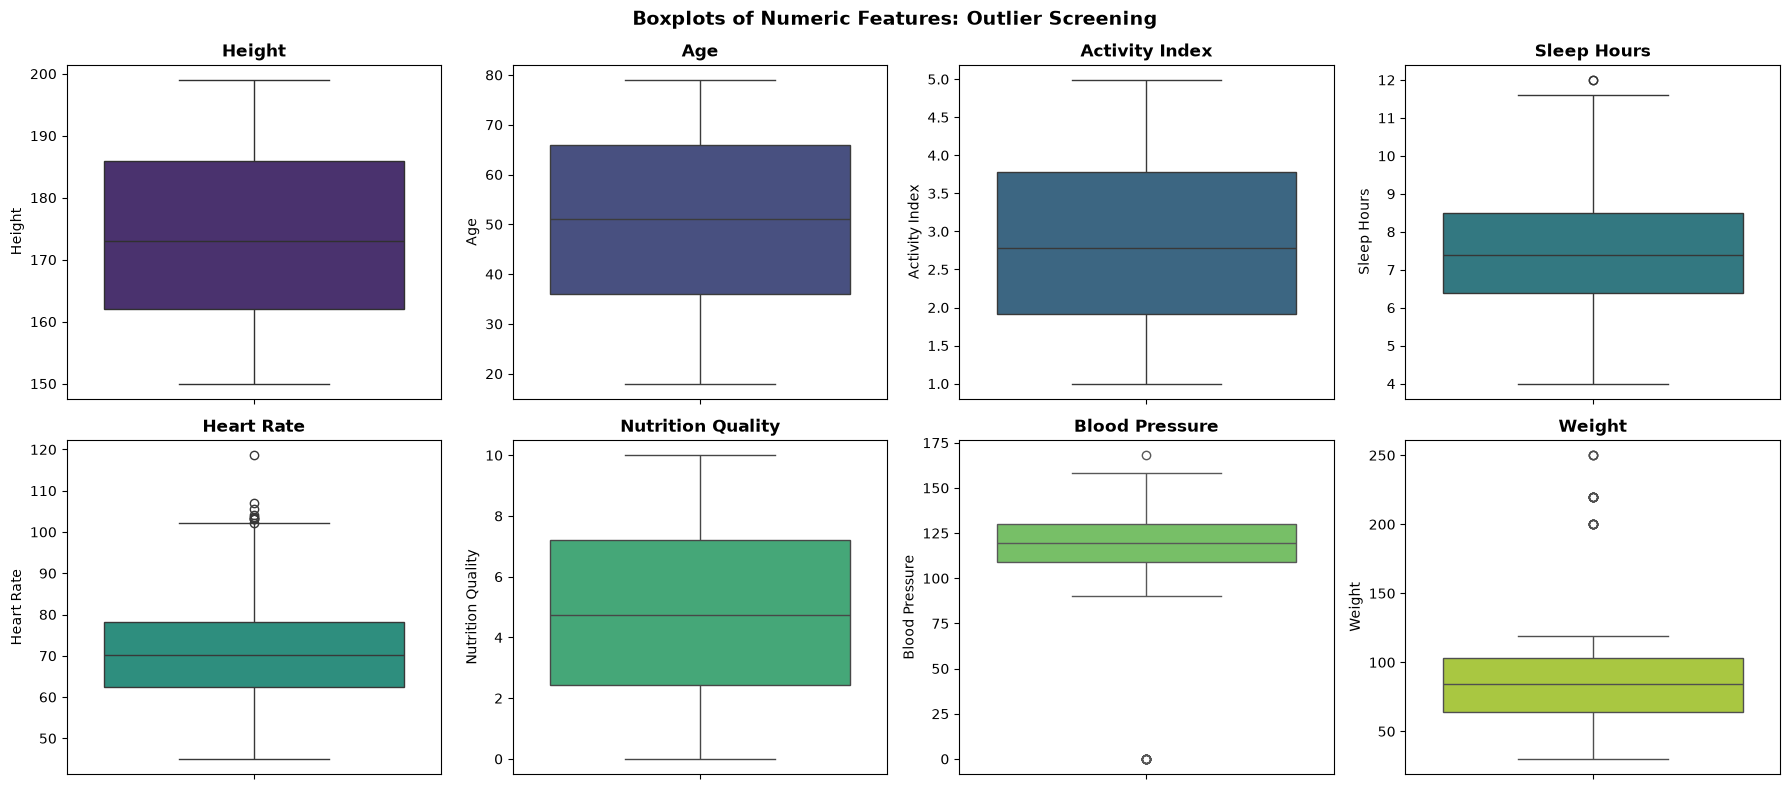

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    sns.boxplot(y=df[col], ax=axes[i], color=sns.color_palette('viridis', len(numeric_cols))[i])
    axes[i].set_title(col, fontweight='bold')
for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])
plt.suptitle('Boxplots of Numeric Features: Outlier Screening', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


**Draft notes:**

- The systematic scan confirms Weight (1.12%) and Blood Pressure (0.90%) as the two features with the most statistical outliers, with Heart Rate (0.61%) and Sleep Hours (0.14%) worth a smaller mention. Four features (Activity Index, Age, Height, Nutrition Quality) show zero IQR-flagged outliers: worth stating explicitly, since it shows the scan was run across everything, not cherry-picked.


**Domain-implausible values (a distinct category of noise)**

In [13]:
invalid_bp = (df['Blood Pressure'] <= 40).sum()
print(f"Blood Pressure <= 40 (implausible systolic reading): {invalid_bp} rows")
print(df.loc[df['Blood Pressure'] <= 40, 'Blood Pressure'].value_counts())
print()

weight_extreme_counts = df.loc[(df['Weight'] < 35) | (df['Weight'] > 150), 'Weight'].value_counts()
print('Extreme Weight values and their frequency:')
print(weight_extreme_counts)

Blood Pressure <= 40 (implausible systolic reading): 12 rows
Blood Pressure
0.0    12
Name: count, dtype: int64

Extreme Weight values and their frequency:
Weight
220.0    8
200.0    7
30.0     4
250.0    3
Name: count, dtype: int64


**Draft notes:**

- Blood Pressure has 12 rows sitting exactly at 0: a systolic reading of 0 mmHg isn't physiologically possible in a living person, so these are very likely a missing-value placeholder encoded as zero.
- Weight shows repeated identical extreme values (e.g. 220 and 250 appearing multiple times): repeated identical outliers like this often point to synthetic/injected values or a data entry default, rather than natural biological variation.
- These are a distinct category from the *statistical* outliers found above: a statistical outlier can still be a genuine (if unusual) real measurement, whereas these specific values are noise in the stronger sense: almost certainly not real measurements at all.


### Summary of Data Quality Findings

- **Missing values**: uneven across columns: Activity Index stands out at ~51% missing (shown to be statistically unrelated to Fitness Level via chi-square test), a smaller cluster of features (Blood Pressure, Sleep Hours, Heart Rate) at 8-11%, and a distinct small batch of ~12 rows with *simultaneous* missingness across five otherwise-mostly-complete columns, suggesting a systematic collection issue rather than random gaps.
- **Duplicates**: minimal: 0.06% of rows.
- **Noise**: a systematic IQR scan found Weight and Blood Pressure as the main sources of statistical outliers; separately, Blood Pressure = 0 and repeated identical extreme Weight values were identified as domain-implausible noise likely reflecting data entry or synthetic-generation artifacts rather than genuine measurements.

### Handling These Issues

Based on the issues identified above, we now clean the data. We work on a copy (`df_clean`) so the original `df` stays untouched for reference.


In [14]:
decision_table = pd.DataFrame([
    {'Issue': 'Near-empty ("ghost") rows', 'Count': 11, 'Action': 'Drop',
     'Why': 'Missing >=80% of columns; no usable signal'},
    {'Issue': 'Exact duplicates', 'Count': 1, 'Action': 'Drop',
     'Why': 'Inflates row count; adds no new information'},
    {'Issue': 'Blood Pressure == 0', 'Count': 12, 'Action': 'Set to NaN, then median-impute',
     'Why': 'Systolic 0 mmHg is physiologically impossible'},
    {'Issue': 'Weight outside [35, 150]', 'Count': 22, 'Action': 'Set to NaN, then median-impute',
     'Why': 'Repeated identical extremes suggest synthetic/injected values'},
    {'Issue': 'Activity Index missing (~51%)', 'Count': 816, 'Action': "Flag 'was missing' + median-impute",
     'Why': 'Too much to drop the column; missingness itself may be informative'},
    {'Issue': 'Remaining scattered missing values', 'Count': '<2% each', 'Action': 'Median/mode-impute',
     'Why': 'Small, scattered gaps with no evidence of a systematic cause'},
])
decision_table

,Issue,Count,Action,Why
0,"Near-empty (""ghost"") rows",11,Drop,Missing >=80% of columns; no usable signal
1,Exact duplicates,1,Drop,Inflates row count; adds no new information
2,Blood Pressure == 0,12,"Set to NaN, then median-impute",Systolic 0 mmHg is physiologically impossible
3,"Weight outside [35, 150]",22,"Set to NaN, then median-impute",Repeated identical extremes suggest synthetic/...
4,Activity Index missing (~51%),816,Flag 'was missing' + median-impute,Too much to drop the column; missingness itsel...
5,Remaining scattered missing values,<2% each,Median/mode-impute,"Small, scattered gaps with no evidence of a sy..."


In [15]:
df_clean = df.copy()
print(f"Starting shape: {df_clean.shape}")

Starting shape: (1610, 12)


**1. Near-empty ("ghost") rows → drop**

Rows missing at least 80% of their columns carry almost no usable information: dropped before any other cleaning step.


In [16]:
ghost_threshold = int(0.8 * len(df_clean.columns))
ghost_rows = df_clean[df_clean.isnull().sum(axis=1) >= ghost_threshold]
df_clean = df_clean.drop(index=ghost_rows.index).reset_index(drop=True)
print(f"Dropped {len(ghost_rows)} ghost row(s). Shape now: {df_clean.shape}")

Dropped 8 ghost row(s). Shape now: (1602, 12)


**2. Blood Pressure == 0 → treat as missing**

A systolic reading of 0 is not physiologically possible, so we recode these as NaN rather than treating them as valid low readings.

In [17]:
bp_zero_count = (df_clean['Blood Pressure'] == 0).sum()
df_clean.loc[df_clean['Blood Pressure'] == 0, 'Blood Pressure'] = pd.NA
df_clean['Blood Pressure'] = pd.to_numeric(df_clean['Blood Pressure'])
print(f"Recoded {bp_zero_count} Blood Pressure values (0 -> NaN)")

Recoded 12 Blood Pressure values (0 -> NaN)


**3. Weight: repeated extreme values → treat as noise, recode as missing**

The identical repeated values at 220 and 250 look synthetic rather than genuine measurements, so we recode them as NaN too.


In [18]:
weight_noise_mask = (df_clean['Weight'] < 35) | (df_clean['Weight'] > 150)
weight_noise_count = weight_noise_mask.sum()
df_clean.loc[weight_noise_mask, 'Weight'] = pd.NA
df_clean['Weight'] = pd.to_numeric(df_clean['Weight'])
print(f"Recoded {weight_noise_count} extreme Weight values (>150 or <35) -> NaN")

Recoded 22 extreme Weight values (>150 or <35) -> NaN


**4. Duplicates → drop**

In [19]:
before = len(df_clean)
df_clean = df_clean.drop_duplicates()
print(f"Dropped {before - len(df_clean)} duplicate row(s). New shape: {df_clean.shape}")

Dropped 0 duplicate row(s). New shape: (1602, 12)


**5. Activity Index (~51% missing): add a "was missing" flag, then impute**

Given how much of this column is missing, we don't just impute silently. We first record *which* rows were missing (in case missingness itself turns out to be informative: e.g. correlated with Fitness Level), then fill the gaps with the median so the column stays usable for later analysis.

**Caveat to raise in the video:** this imputation is a strong assumption given the scale of missingness: any correlation or clustering results involving Activity Index later on should be treated with caution.


In [20]:
df_clean['Activity_Index_was_missing'] = df_clean['Activity Index'].isna()
activity_median = df_clean['Activity Index'].median()
df_clean['Activity Index'] = df_clean['Activity Index'].fillna(activity_median)
print(f"Activity Index imputed with median = {activity_median}")
print(f"Flag column added: {df_clean['Activity_Index_was_missing'].sum()} rows flagged as originally missing")

Activity Index imputed with median = 2.78
Flag column added: 810 rows flagged as originally missing


**6. Remaining missing values: impute the rest**

For the remaining numeric columns (Sleep Hours, Heart Rate, Nutrition Quality, Blood Pressure, Weight, Height, Age) we use median imputation, since it's robust to the outliers/skew we found earlier. For the categorical columns (Gender, Smoker) we use the mode.


In [21]:
# Final check: confirm no missing values remain
print("Remaining missing values per column:")
print(df_clean.isna().sum())
print(f"\nFinal cleaned shape: {df_clean.shape}")


Remaining missing values per column:
Height                           4
Age                              2
Gender                           4
Smoker                           3
Activity Index                   0
Sleep Hours                    135
Heart Rate                     126
Nutrition Quality                1
Blood Pressure                 173
Weight                          25
Fitness Level                    0
Activity_Index_missing_flag      0
Activity_Index_was_missing       0
dtype: int64

Final cleaned shape: (1602, 13)


### Before vs. After Cleaning

In [22]:
print(f"Shape before cleaning: {df.shape}")
print(f"Shape after cleaning:  {df_clean.shape}")
print(f"\nMissing values remaining:\n{df_clean.isna().sum().sum()} total")
print()
df_clean.describe().T

Shape before cleaning: (1610, 12)
Shape after cleaning:  (1602, 13)

Missing values remaining:
473 total



,count,mean,std,min,25%,50%,75%,max
Height,1598.0,174.080100,14.380676,150.0,162.000,173.00,186.00,199.00
Age,1600.0,50.521250,17.871497,18.0,36.000,51.00,66.00,79.00
Activity Index,1602.0,2.827434,0.794624,1.0,2.780,2.78,2.78,4.99
Sleep Hours,1467.0,7.431152,1.499842,4.0,6.400,7.40,8.50,12.00
Heart Rate,1476.0,70.233469,11.848808,45.0,62.375,70.10,78.30,118.60
Nutrition Quality,1601.0,4.846471,2.851291,0.0,2.420,4.73,7.21,10.00
Blood Pressure,1429.0,119.834500,14.568767,90.0,109.400,119.90,130.00,168.10
Weight,1577.0,82.835764,21.897379,35.0,64.000,83.00,102.00,119.00


**Draft notes: rewrite in your own words for the video:**

- The target is **imbalanced**: Low = 1,204 rows (74.8%), High = 406 rows (25.2%): roughly 3:1.
- Worth flagging as a limitation to think about later (e.g. for Assignment 2): a model that just predicted "Low" every time would already be ~75% "accurate" without learning anything meaningful, so accuracy alone would be a misleading metric here.


## Data analysis

Expand the notebook for your Exporatory Data Analysis.

### Feature Engineering: BMI

Height and Weight individually are only weakly correlated with Fitness Level, but their *combination*: Body Mass Index: is a more standard fitness-relevant measure than either feature alone. Adding it gives the analysis (and any later modelling) a domain-informed feature to compare against the raw measurements.


count    1576.000000
mean       27.880912
std         8.756836
min         8.838161
25%        20.832102
50%        27.385292
75%        33.781451
max        52.888889
Name: BMI, dtype: float64


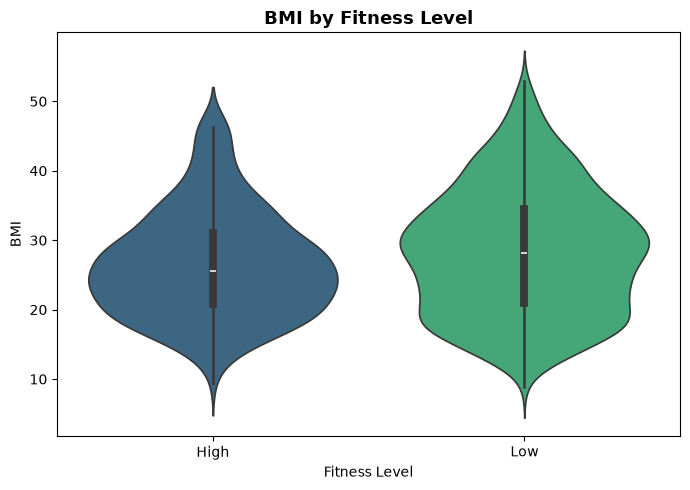

In [23]:
df_clean['BMI'] = df_clean['Weight'] / ((df_clean['Height'] / 100) ** 2)
print(df_clean['BMI'].describe())

plt.figure(figsize=(7, 5))
sns.violinplot(data=df_clean, x='Fitness Level', y='BMI', hue='Fitness Level', palette='viridis', legend=False)
plt.title('BMI by Fitness Level', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

**Draft notes:**

- BMI's range here is wider than clinically typical (some very low and very high values): a direct consequence of the Height/Weight data quality issues already discussed, even after cleaning. Worth being upfront about this rather than presenting BMI as if it were pristine.
- Compare the spread of BMI between High and Low fitness groups: if it's not dramatically different, that's consistent with the earlier finding that Height and Weight individually showed almost no correlation with Fitness Level.


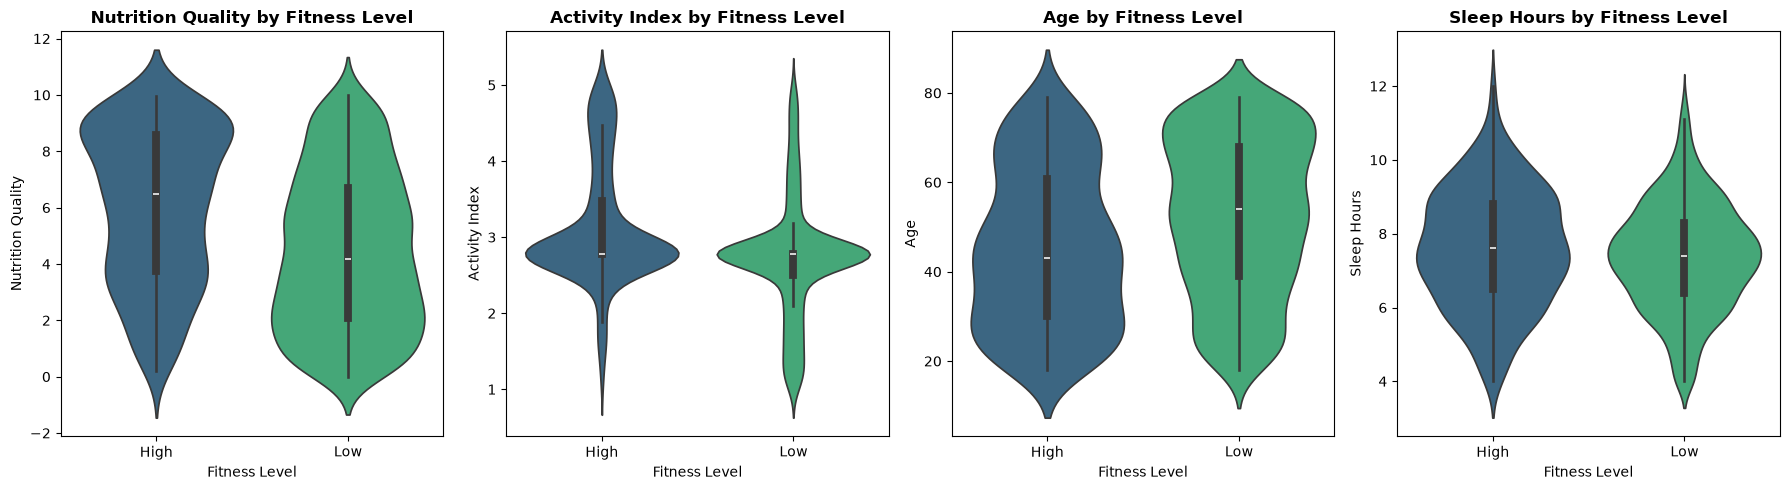

In [24]:
key_features = ['Nutrition Quality', 'Activity Index', 'Age', 'Sleep Hours']

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for i, col in enumerate(key_features):
    sns.violinplot(data=df_clean, x='Fitness Level', y=col, hue='Fitness Level',
                   palette='viridis', legend=False, ax=axes[i])
    axes[i].set_title(f'{col} by Fitness Level', fontweight='bold')
plt.tight_layout()
plt.show()

**Draft notes:**

- These four features were chosen because they showed the strongest (though still modest) relationship with Fitness Level in the correlation check below: worth explaining *why* you picked these four rather than just showing all eight.
- Look for shifts in the shape/median of each violin between High and Low groups, not just whether the boxes overlap.


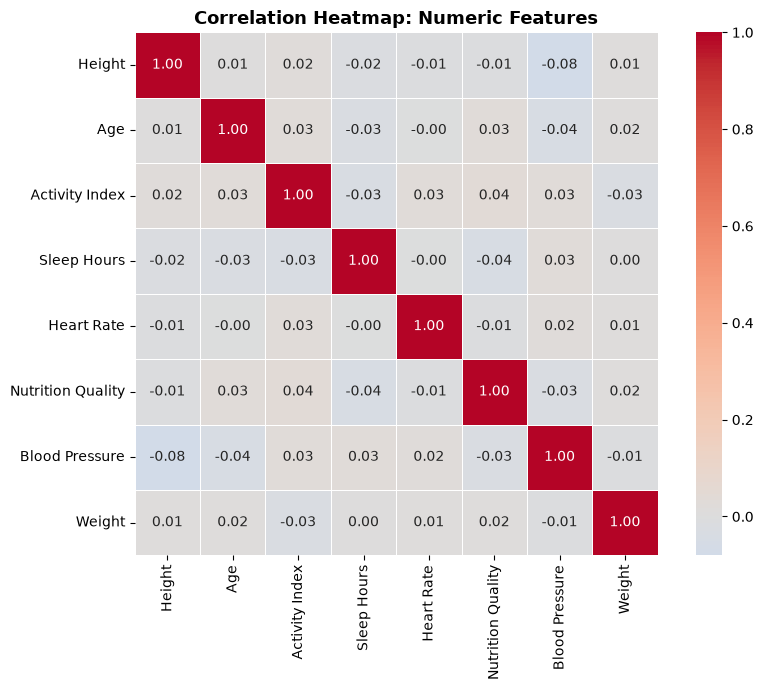

In [25]:
numeric_cols = ['Height', 'Age', 'Activity Index', 'Sleep Hours', 'Heart Rate',
                'Nutrition Quality', 'Blood Pressure', 'Weight']

corr_matrix = df_clean[numeric_cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5)
plt.title('Correlation Heatmap: Numeric Features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


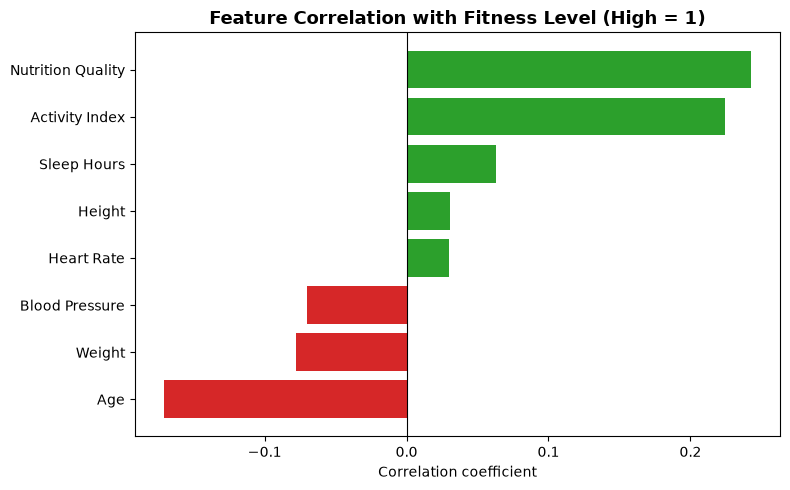

In [26]:
df_clean['Fitness_binary'] = (df_clean['Fitness Level'] == 'High').astype(int)
target_corr = df_clean[numeric_cols + ['Fitness_binary']].corr()['Fitness_binary'].drop('Fitness_binary').sort_values()

plt.figure(figsize=(8, 5))
colors = ['#d62728' if v < 0 else '#2ca02c' for v in target_corr.values]
plt.barh(target_corr.index, target_corr.values, color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Feature Correlation with Fitness Level (High = 1)', fontsize=13, fontweight='bold')
plt.xlabel('Correlation coefficient')
plt.tight_layout()
plt.show()

**Draft notes:**

- Feature-to-feature correlations (the heatmap) are all very weak: no strong multicollinearity between the numeric predictors.
- Feature-to-target correlations are modest but clearest for **Nutrition Quality (+0.24)**, **Activity Index (+0.23)**, and **Age (-0.17)**: i.e. better nutrition and more activity lean toward "High" fitness, older age leans toward "Low."
- None of these correlations are strong on their own: worth being honest about that rather than overstating it. This suggests Fitness Level isn't explained well by any single feature in isolation, which is itself an insight (and a reason multivariate/clustering techniques are worth trying next).


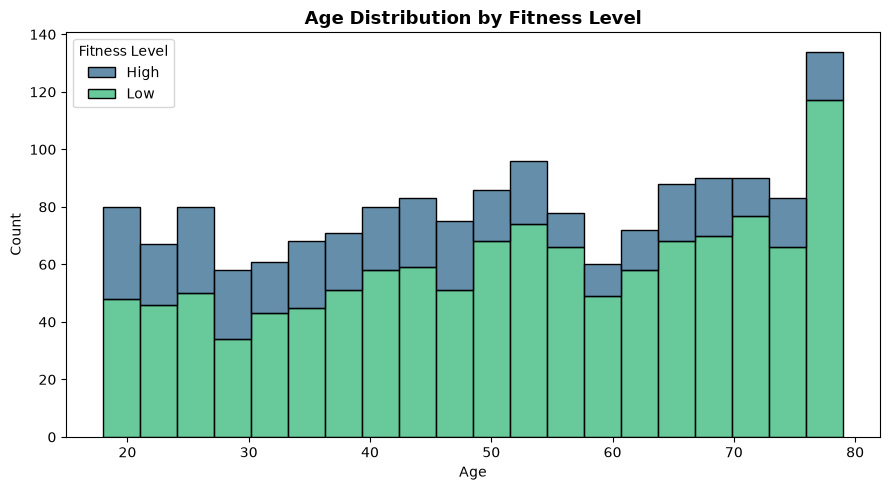

In [27]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df_clean, x='Age', hue='Fitness Level', multiple='stack', bins=20, palette='viridis')
plt.title('Age Distribution by Fitness Level', fontsize=13, fontweight='bold')
plt.xlabel('Age')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

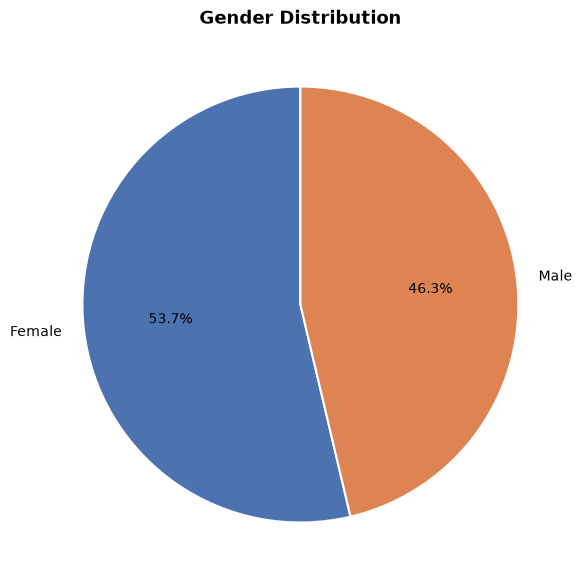

In [28]:
gender_counts = df_clean['Gender'].value_counts()

plt.figure(figsize=(6, 6))
colors = ['#4C72B0', '#DD8452']
plt.pie(gender_counts.values, labels=gender_counts.index, autopct='%1.1f%%',
        colors=colors, startangle=90, wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
plt.title('Gender Distribution', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

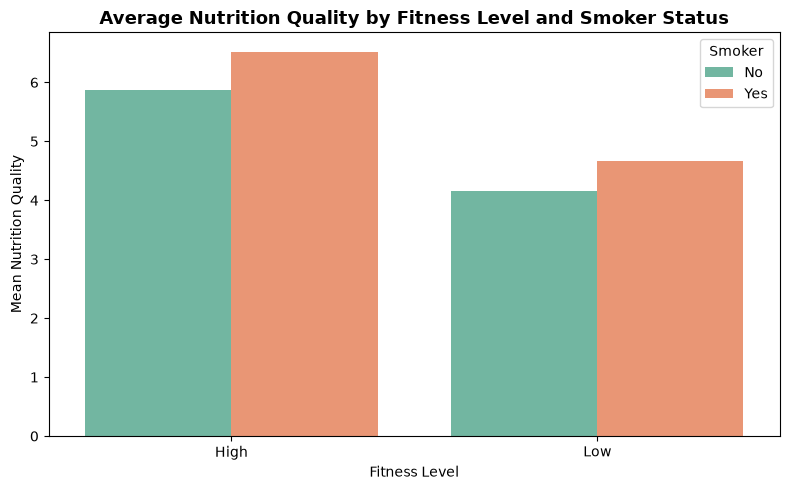

In [29]:
grp = df_clean.groupby(['Fitness Level', 'Smoker'])['Nutrition Quality'].mean().reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(data=grp, x='Fitness Level', y='Nutrition Quality', hue='Smoker', palette='Set2')
plt.title('Average Nutrition Quality by Fitness Level and Smoker Status', fontsize=13, fontweight='bold')
plt.ylabel('Mean Nutrition Quality')
plt.tight_layout()
plt.show()

**Draft notes:**

- **Histogram:** Age distribution looks fairly even across the range for the "Low" group, but check whether "High" fitness skews toward any particular age band: this ties back to the -0.17 correlation found earlier (older leaning slightly toward "Low").
- **Pie chart:** Gender split is close to even (869 Female / 740 Male, ~54%/46%): not a major imbalance, but we checked it as part of understanding the dataset's composition.
- **Bar chart:** this one throws up something worth talking through critically rather than glossing over: smokers show a *higher* average Nutrition Quality than non-smokers in both fitness groups, which runs against intuition. This a real pattern, a coincidence in a synthetic dataset, or a sign the two variables aren't really related and this small difference is just noise? 


## AI Declaration and Reflection

### AI Tools Declaration

I used ChatGPT (GPT-4o) and GitHub Copilot during the development of this assignment. These tools were used as programming assistants to help debug Python errors, look up pandas / scipy / seaborn syntax, and tidy plot formatting. They were not used to invent the data-quality decisions or to write the scientific interpretations unsupervised.

### AI Tools Reflection and Lessons Learnt

Using GenAI for dataframe checks and plot boilerplate saved time. It was less reliable on methodological judgement: for example, generic advice sometimes pushed dropping rows with missing values even when that would throw away about half the dataset because of Activity Index. The useful pattern was to decide the EDA findings and cleaning rules myself first (ghost rows, Blood Pressure zeros, Weight noise, median imputation, BMI), and only then ask AI for syntax help implementing that plan.

### AI Academic Integrity

All exploratory findings, cleaning justifications, and critical interpretations in this notebook are my own work. GenAI was limited to syntax support, debugging, and formatting. I checked every generated snippet against the dataset evidence before keeping it.
